### Import libraries
os, gc, random, warnings, re, math, numpy, pandas, matplotlib, seaborn, cv2, pydicom, tqdm, sklearn, torch, torchvision

In [1]:
import os
import gc
import random
import warnings
import re
import math

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import cv2
import pydicom

from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms

from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128


### Set device to GPU if available else CPU, check GPU properties

In [2]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(
                0
            ).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB


### Set directory names

In [3]:
INPUT_ROOT = "/kaggle/input"

print(
    os.listdir(INPUT_ROOT)
)

DATA_DIR = (
    "/kaggle/input/competitions/"
    "rsna-knee-abnormality-detection"
)

print(
    os.listdir(DATA_DIR)
)

['competitions', 'datasets']
['test_series.csv', 'train_series.csv', 'sample_submission.csv', 'test_series', 'train_series', 'train.csv', 'test.csv']


### Read data files

In [4]:
train = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "train.csv"
    )
)

train_series = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "train_series.csv"
    )
)

test = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "test.csv"
    )
)

test_series = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "test_series.csv"
    )
)

sample_submission = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "sample_submission.csv"
    )
)

print(
    "Train:",
    train.shape
)

print(
    "Train series:",
    train_series.shape
)

print(
    "Test:",
    test.shape
)

print(
    "Test series:",
    test_series.shape
)

print(
    "Sample submission:",
    sample_submission.shape
)

Train: (4407, 14)
Train series: (24371, 5)
Test: (3, 1)
Test series: (15, 5)
Sample submission: (3, 13)


### Save targets, print stats

In [5]:
TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

NUM_CLASSES = len(TARGETS)

print(
    "Number of targets:",
    NUM_CLASSES
)

for i, target in enumerate(TARGETS):
    print(i, target)

print(
    "Total studies:",
    len(train)
)

print(
    "\nNon-null labels:"
)

print(
    train[TARGETS].notna().sum()
)

Number of targets: 12
0 ACL
1 MCL
2 Medial Meniscus
3 Lateral Meniscus
4 Medial OA
5 Lateral OA
6 PF OA
7 Effusion
8 Synovitis
9 Baker's
10 Contusion
11 Fracture
Total studies: 4407

Non-null labels:
ACL                 58
MCL                 58
Medial Meniscus     58
Lateral Meniscus    58
Medial OA           58
Lateral OA          58
PF OA               58
Effusion            58
Synovitis           58
Baker's             58
Contusion           58
Fracture            58
dtype: int64


### Create masks for labelled and unlabelled series

In [6]:
labeled_mask = (
    train[TARGETS]
    .notna()
    .all(axis=1)
)

unlabeled_mask = (
    train[TARGETS]
    .isna()
    .all(axis=1)
)

labeled_data = train[
    labeled_mask
].copy()

unlabeled_data = train[
    unlabeled_mask
].copy()

print(
    "Officially labeled studies:",
    len(labeled_data)
)

print(
    "Unlabeled studies:",
    len(unlabeled_data)
)

missing_pattern = (
    train[TARGETS]
    .isna()
    .astype(int)
    .value_counts()
)

display(
    missing_pattern
)

official_counts = (
    labeled_data[TARGETS]
    .sum()
    .sort_values(
        ascending=False
    )
)

display(
    official_counts.to_frame(
        "Positive Cases"
    )
)

Officially labeled studies: 58
Unlabeled studies: 4349


ACL  MCL  Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA  PF OA  Effusion  Synovitis  Baker's  Contusion  Fracture
1    1    1                1                 1          1           1      1         1          1        1          1           4349
0    0    0                0                 0          0           0      0         0          0        0          0             58
Name: count, dtype: int64

,Positive Cases
Effusion,35.0
Synovitis,27.0
Medial Meniscus,26.0
ACL,24.0
Lateral Meniscus,23.0
PF OA,21.0
Contusion,19.0
Fracture,18.0
Medial OA,15.0
Baker's,12.0


### Plot positive cases

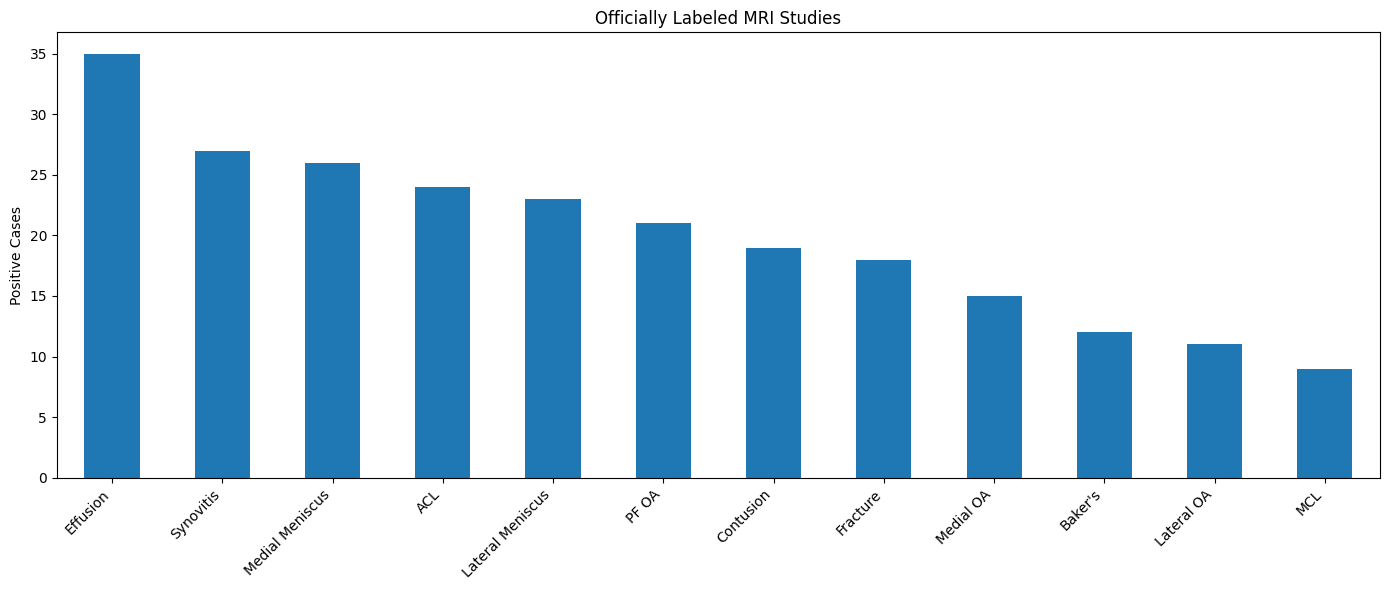

In [7]:
plt.figure(
    figsize=(14, 6)
)

official_counts.plot(
    kind="bar"
)

plt.title(
    "Officially Labeled MRI Studies"
)

plt.ylabel(
    "Positive Cases"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [8]:
display(
    train_series.head()
)

print(
    train_series[
        "Anatomical_Plane"
    ].value_counts()
)

print(
    train_series[
        "Fluid_Sensitive"
    ].value_counts()
)

print()

print(
    train_series[
        "Fat_Suppression"
    ].value_counts()
)

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal


Anatomical_Plane
Sagittal    9864
Coronal     8609
Axial       5898
Name: count, dtype: int64
Fluid_Sensitive
1    14010
0    10361
Name: count, dtype: int64

Fat_Suppression
1    14010
0    10361
Name: count, dtype: int64


### Save data file paths

In [9]:
TRAIN_SERIES_DIR = os.path.join(
    DATA_DIR,
    "train_series"
)

TEST_SERIES_DIR = os.path.join(
    DATA_DIR,
    "test_series"
)

print(
    TRAIN_SERIES_DIR
)

print(
    TEST_SERIES_DIR
)

/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series
/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series


### Define function to get dicom paths

In [10]:
def get_dicom_paths(
    study_id,
    series_id,
    base_dir
):

    series_path = os.path.join(
        base_dir,
        str(study_id),
        str(series_id)
    )

    if not os.path.exists(
        series_path
    ):
        return []

    paths = []

    for filename in os.listdir(
        series_path
    ):

        if filename.lower().endswith(
            ".dcm"
        ):

            paths.append(
                os.path.join(
                    series_path,
                    filename
                )
            )

    return paths

### Define function to get sorted dicom paths based on instance number of dcm

In [11]:
def get_sorted_dicom_paths(
    study_id,
    series_id,
    base_dir
):

    paths = get_dicom_paths(
        study_id,
        series_id,
        base_dir
    )

    records = []

    for path in paths:

        try:

            dcm = pydicom.dcmread(
                path,
                stop_before_pixels=True
            )

            instance_number = getattr(
                dcm,
                "InstanceNumber",
                0
            )

            records.append(
                (
                    instance_number,
                    path
                )
            )

        except Exception:
            continue

    records.sort(
        key=lambda x: x[0]
    )

    return [
        path
        for _, path in records
    ]

### Define function to read dicom image as array, resize, and normalize

In [12]:
def read_dicom(
    path
):

    dcm = pydicom.dcmread(
        path
    )

    image = dcm.pixel_array.astype(
        np.float32
    )

    if getattr(
        dcm,
        "PhotometricInterpretation",
        ""
    ) == "MONOCHROME1":

        image = (
            image.max() - image
        )

    # Apply rescale slope/intercept
    slope = float(
        getattr(
            dcm,
            "RescaleSlope",
            1
        )
    )

    intercept = float(
        getattr(
            dcm,
            "RescaleIntercept",
            0
        )
    )

    image = (
        image * slope
        + intercept
    )

    # Percentile normalization
    low = np.percentile(
        image,
        1
    )

    high = np.percentile(
        image,
        99
    )

    if high > low:

        image = (
            image - low
        ) / (
            high - low
        )

    else:

        image = np.zeros_like(
            image
        )

    image = np.clip(
        image,
        0,
        1
    )

    return image

### Define function to return max num_slices evenly spaced image paths

In [13]:
def select_representative_slices(
    paths,
    num_slices=8
):

    if len(paths) == 0:
        return []

    if len(paths) <= num_slices:

        return paths

    indices = np.linspace(
        0,
        len(paths) - 1,
        num_slices
    ).astype(int)

    return [
        paths[i]
        for i in indices
    ]

### Define function to return max_series series from one study based on priority order

In [14]:
def select_series(
    study_id,
    series_df,
    max_series=3
):

    df = series_df[
        series_df[
            "StudyInstanceUID"
        ] == study_id
    ].copy()

    if len(df) == 0:
        return df

    # Priority:
    # 1. Fluid-sensitive
    # 2. Fat suppression
    # 3. Anatomical plane

    df["priority"] = (
        df["Fluid_Sensitive"].astype(int)
        * 2
        +
        df["Fat_Suppression"].astype(int)
    )

    df = df.sort_values(
        "priority",
        ascending=False
    )

    return df.head(
        max_series
    )

In [15]:
sample_study = labeled_data.iloc[0][
    "StudyInstanceUID"
]

print(
    "Sample study:",
    sample_study
)

sample_series = select_series(
    sample_study,
    train_series,
    max_series=3
)

display(
    sample_series
)

series_id = sample_series.iloc[0][
    "SeriesInstanceUID"
]

paths = get_sorted_dicom_paths(
    sample_study,
    series_id,
    TRAIN_SERIES_DIR
)

print(
    "Number of slices:",
    len(paths)
)

Sample study: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane,priority
165,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.21497837050858589852...,1,1,Coronal,3
167,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,1,1,Axial,3
166,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,1,1,Sagittal,3


Number of slices: 30


### Print images from sample series

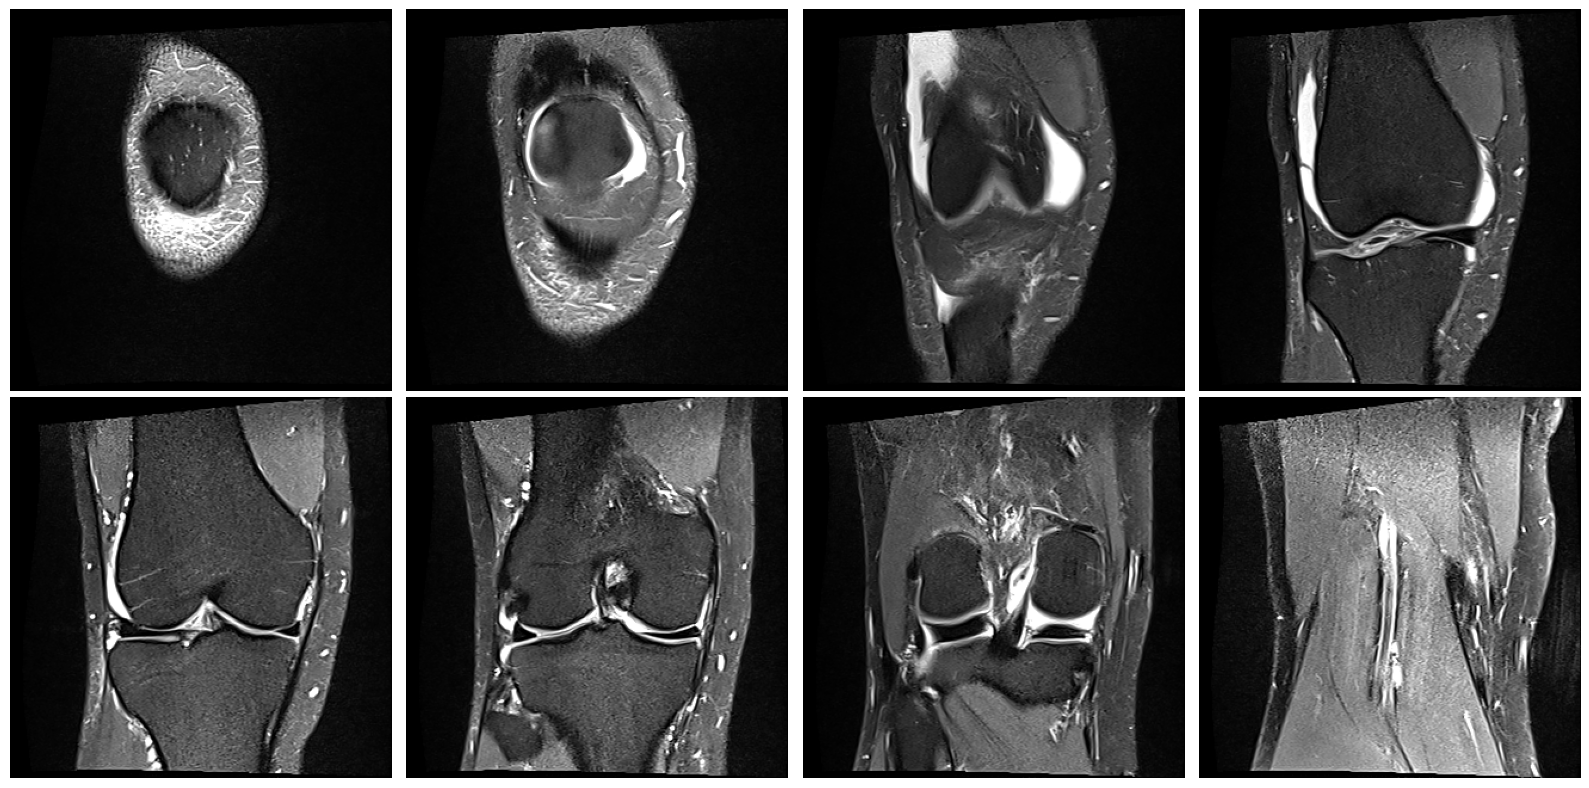

In [16]:
selected_paths = (
    select_representative_slices(
        paths,
        num_slices=8
    )
)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)

for ax, path in zip(
    axes.ravel(),
    selected_paths
):

    image = read_dicom(
        path
    )

    ax.imshow(
        image,
        cmap="gray"
    )

    ax.axis("off")

plt.tight_layout()

plt.show()

### Print some radiology reports

In [17]:
for i in range(
    min(10, len(train))
):

    print(
        "=" * 80
    )

    print(
        train.iloc[i]["Report"]
    )

Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame.
[DATE]: * MR Knie Rechts 15ch AA Klinische Inlichtingen: [DATE]. Diagnostische vraagstellling: Meniscusscheur/mediaal? Scanprotocol (DRB) : sag intermediair gewogen seq zonder en met fs, ax/ cor pd gewogen seq fs, cor T1 gewogen seq Bevindingen:
Hallazgos:
No hay alteraciones en significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Aumento de señal del cuerno posterior del menisco medial que no impresiona contactar con la
superficie articular, sin caracteres propios de rotura.
Menisco lateral de morfología y señal conservada, sin signos de rotura.
Úlceras condrales de espesor parcial con fenómenos condrales reparativos de la re

### Define function to preprocess reports
Handle nulls \
Convert to lowercase \
Replace accented characters with plain ASCII \
Replace line breaks and remove trailing whitespace

In [18]:
def normalize_text(
    text
):

    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Normalize accents
    import unicodedata

    text = unicodedata.normalize(
        "NFKD",
        text
    )

    text = "".join(
        char
        for char in text
        if not unicodedata.combining(
            char
        )
    )

    # Replace line breaks
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()

### Define function to assing weak labels

In [19]:
pip install -U bitsandbytes>=0.46.1

Note: you may need to restart the kernel to use updated packages.


In [20]:
# ============================================================ 
# Prompt 
# ============================================================ 

SYSTEM_PROMPT = f""" You are a medical report classification assistant. Classify the following 12 abnormalities from the radiology report: 

- ACL: anterior cruciate ligament tear/injury 
- MCL: medial collateral ligament tear/injury 
- Medial Meniscus: tear or other abnormality of the medial meniscus 
- Lateral Meniscus: tear or other abnormality of the lateral meniscus 
- Medial OA: osteoarthritis/degenerative changes of the medial tibiofemoral compartment 
- Lateral OA: osteoarthritis/degenerative changes of the lateral tibiofemoral compartment 
- PF OA: osteoarthritis/degenerative changes of the patellofemoral compartment 
- Effusion: abnormal joint fluid / joint effusion 
- Synovitis: inflammation/thickening of the synovium 
- Baker's: Baker's (popliteal) cyst 
- Contusion: bone contusion / bone bruise / traumatic marrow edema 
- Fracture: fracture of a knee-related bone 

For each abnormality output exactly one of: 

1 = clearly PRESENT 
0 = clearly ABSENT or not mentioned 
0.5 = uncertain, equivocal, suspected, or insufficient evidence 

Rules: 
- Use 1 only when the report supports the abnormality. 
- Use 0 when it is explicitly absent/normal OR not mentioned. 
- Do not infer an abnormality from a related finding. 
- Pay close attention to negation, anatomy, and compartment. 
- If the report is equivocal or uncertain, use 0.5. 
- Return ONLY a valid JSON object. No explanations or markdown. 

Example: 
{{ 
"ACL": 1, 
"MCL": 0, 
"Medial Meniscus": 0.5 
}} """ 

In [ ]:
import os
import json
import torch
import pandas as pd
from tqdm.auto import tqdm
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# ============================================================
# Model
# ============================================================

MODEL_NAME = "Qwen/Qwen3-8B"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quant_config,
    device_map="auto",
    trust_remote_code=True,
)

model.eval()


# ============================================================
# Checkpoint configuration
# ============================================================

CHECKPOINT_DIR = "/kaggle/working"
CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "qwen_weak_labels_checkpoint.json"
)


# ============================================================
# Parsing
# ============================================================

def parse_qwen_labels(text):

    text = text.strip()

    # Remove markdown code fences if present
    if text.startswith("```"):
        text = text.strip("`")

    if text.startswith("json"):
        text = text[4:].strip()

    # Find JSON object
    start = text.find("{")
    end = text.rfind("}")

    if start == -1 or end == -1:
        return {target: 0.5 for target in TARGETS}

    try:
        result = json.loads(text[start:end + 1])

    except json.JSONDecodeError:
        return {target: 0.5 for target in TARGETS}

    labels = {}

    for target in TARGETS:

        value = result.get(target, 0.5)

        if value in [0, 1, 0.5]:
            labels[target] = float(value)
        else:
            labels[target] = 0.5

    return labels


# ============================================================
# Checkpoint utilities
# ============================================================

def save_checkpoint(labels, processed_reports):

    checkpoint = {
        "processed_reports": processed_reports,
        "labels": labels,
    }

    # Write to temporary file first, then replace.
    # This prevents a partially written checkpoint if the
    # notebook gets interrupted during saving.
    temp_file = CHECKPOINT_FILE + ".tmp"

    with open(temp_file, "w") as f:
        json.dump(checkpoint, f)

    os.replace(temp_file, CHECKPOINT_FILE)


def load_checkpoint():

    if not os.path.exists(CHECKPOINT_FILE):
        return [], 0

    print(f"Loading checkpoint: {CHECKPOINT_FILE}")

    with open(CHECKPOINT_FILE, "r") as f:
        checkpoint = json.load(f)

    labels = checkpoint.get("labels", [])
    processed_reports = checkpoint.get(
        "processed_reports",
        len(labels),
    )

    print(
        f"Checkpoint found: {processed_reports:,} reports already processed."
    )

    return labels, processed_reports


# ============================================================
# Batched inference with checkpointing
# ============================================================

def qwen_classify_reports(reports, batch_size=8):

    # --------------------------------------------------------
    # Load previous checkpoint
    # --------------------------------------------------------

    all_labels, start_index = load_checkpoint()

    # Safety check
    if start_index > len(reports):
        raise ValueError(
            f"Checkpoint contains {start_index} reports, "
            f"but current dataset only has {len(reports)} reports."
        )

    # Already completed
    if start_index == len(reports):
        print("All reports have already been processed.")
        return all_labels

    print(
        f"Starting inference from report "
        f"{start_index:,} / {len(reports):,}"
    )

    # --------------------------------------------------------
    # Process remaining reports
    # --------------------------------------------------------

    for start in tqdm(
        range(start_index, len(reports), batch_size),
        desc="Generating weak labels",
    ):

        batch_reports = reports[start:start + batch_size]

        messages = []

        for report in batch_reports:

            messages.append([
                {
                    "role": "system",
                    "content": SYSTEM_PROMPT,
                },
                {
                    "role": "user",
                    "content": (
                        "Classify the following radiology report:\n\n"
                        + str(report)
                    ),
                },
            ])

        # ----------------------------------------------------
        # Apply chat template
        # ----------------------------------------------------

        prompts = [
            tokenizer.apply_chat_template(
                message,
                tokenize=False,
                add_generation_prompt=True,
                enable_thinking=False,
            )
            for message in messages
        ]

        # ----------------------------------------------------
        # Tokenize
        # ----------------------------------------------------

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            padding_side="left",
            truncation=True,
            max_length=4096,
        )

        inputs = {
            key: value.to(model.device)
            for key, value in inputs.items()
        }

        # ----------------------------------------------------
        # Generate
        # ----------------------------------------------------

        with torch.inference_mode():

            outputs = model.generate(
                **inputs,
                max_new_tokens=128,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
            )

        # ----------------------------------------------------
        # Decode only newly generated tokens
        # ----------------------------------------------------

        input_length = inputs["input_ids"].shape[1]

        generated_tokens = outputs[:, input_length:]

        decoded = tokenizer.batch_decode(
            generated_tokens,
            skip_special_tokens=True,
        )

        # ----------------------------------------------------
        # Parse labels
        # ----------------------------------------------------

        batch_labels = [
            parse_qwen_labels(text)
            for text in decoded
        ]

        # Add batch to accumulated results
        all_labels.extend(batch_labels)

        # ----------------------------------------------------
        # SAVE CHECKPOINT
        # ----------------------------------------------------

        processed_reports = start + len(batch_reports)

        save_checkpoint(
            all_labels,
            processed_reports,
        )

        print(
            f"Checkpoint saved: "
            f"{processed_reports:,} / {len(reports):,}"
        )

        # ----------------------------------------------------
        # Release temporary tensors
        # ----------------------------------------------------

        del inputs
        del outputs
        del generated_tokens

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return all_labels


# ============================================================
# Drop-in replacement for the original function
# ============================================================

def create_weak_labels(dataframe, batch_size=4):

    result = dataframe[
        [
            "StudyInstanceUID",
            "Report",
        ]
    ].copy()

    reports = result["Report"].fillna("").tolist()

    label_dicts = qwen_classify_reports(
        reports,
        batch_size=batch_size,
    )

    labels_df = pd.DataFrame(label_dicts)

    # Make sure target ordering is identical
    labels_df = labels_df[TARGETS]

    result = pd.concat(
        [
            result.reset_index(drop=True),
            labels_df.reset_index(drop=True),
        ],
        axis=1,
    )

    return result

In [ ]:
lengths = [
    len(tokenizer.encode(str(r)))
    for r in train["Report"].fillna("")
]

pd.Series(lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99])

### Create weak labels, compare with official

In [ ]:
test_labels = create_weak_labels(
    labeled_data,
    batch_size=4
)

official = labeled_data[
    TARGETS
].copy()

agreement = (
    official[TARGETS]
    .values
    ==
    test_labels[TARGETS]
    .values
)

agreement_rate = (
    agreement.mean(
        axis=0
    )
)

agreement_table = pd.DataFrame({
    "Target": TARGETS,
    "Agreement": agreement_rate
})

display(
    agreement_table
)

In [ ]:
import numpy as np
import pandas as pd

results = []

for target in TARGETS:

    y_true = official[target].values
    y_pred = test_labels[target].values

    # Ignore uncertain Qwen predictions
    mask = y_pred != 0.5

    y_true = y_true[mask]
    y_pred = y_pred[mask]

    # Confusion matrix components
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    # Metrics
    precision = TP / (TP + FP) if (TP + FP) > 0 else np.nan
    recall = TP / (TP + FN) if (TP + FN) > 0 else np.nan

    # Sensitivity = recall
    sensitivity = recall

    specificity = TN / (TN + FP) if (TN + FP) > 0 else np.nan

    results.append({
        "Target": target,
        "Precision": precision,
        "Recall": recall,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Coverage": mask.mean(),
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN,
    })

metrics_df = pd.DataFrame(results)

metrics_df

In [ ]:
weak_labels = create_weak_labels(
    train, batch_size = 2
)

display(
    weak_labels.head()
)

weak_counts = (
    weak_labels[TARGETS]
    .sum()
    .sort_values(
        ascending=False
    )
)

display(
    weak_counts.to_frame(
        "Weak Positive Count"
    )
)

comparison = pd.DataFrame(
    index=TARGETS
)

comparison[
    "Official Positive"
] = (
    labeled_data[TARGETS]
    .sum()
)

comparison[
    "Weak Positive"
] = (
    weak_labels[
        weak_labels[
            "StudyInstanceUID"
        ].isin(
            labeled_data[
                "StudyInstanceUID"
            ]
        )
    ][TARGETS]
    .sum()
)

display(
    comparison
)

official = labeled_data[
    TARGETS
].copy()

weak_official = weak_labels[
    weak_labels[
        "StudyInstanceUID"
    ].isin(
        labeled_data[
            "StudyInstanceUID"
        ]
    )
].copy()

weak_official = (
    weak_official
    .set_index(
        "StudyInstanceUID"
    )
    .loc[
        labeled_data[
            "StudyInstanceUID"
        ]]
)

official.index = (
    labeled_data[
        "StudyInstanceUID"
    ]
)

agreement = (
    official[TARGETS]
    .values
    ==
    weak_official[TARGETS]
    .values
)

agreement_rate = (
    agreement.mean(
        axis=0
    )
)

agreement_table = pd.DataFrame({
    "Target": TARGETS,
    "Agreement": agreement_rate
})

display(
    agreement_table
)

# ============================================================
# Save weak labels
# ============================================================

WEAK_LABELS_PATH = "/kaggle/working/qwen_weak_labels.csv"

weak_labels.to_csv(
    WEAK_LABELS_PATH,
    index=False
)

print(
    f"Saved weak labels to: {WEAK_LABELS_PATH}"
)

print(
    f"Shape: {weak_labels.shape}"
)

### Merge weak labels with training data

In [ ]:
WEAK_LABELS_PATH = "/kaggle/working/qwen_weak_labels.csv"
weak_labels = pd.read_csv(
    WEAK_LABELS_PATH
)

training_data = train[
    [
        "StudyInstanceUID",
        "Report"
    ]
].copy()

training_data = training_data.merge(
    weak_labels,
    on=[
        "StudyInstanceUID",
        "Report"
    ],
    how="left"
)

In [ ]:
w = weak_labels.set_index("StudyInstanceUID").loc[labeled_data["StudyInstanceUID"], TARGETS]
gold = labeled_data.set_index("StudyInstanceUID")[TARGETS]

rows = []
for t in TARGETS:
    p, y = w[t].values, gold[t].values
    keep = p != 0.5
    tp = ((p == 1) & (y == 1)).sum(); fp = ((p == 1) & (y == 0)).sum()
    fn = ((p == 0) & (y == 1)).sum(); tn = ((p == 0) & (y == 0)).sum()
    rows.append(dict(Target=t, Coverage=keep.mean(),
                     Precision=tp / max(tp + fp, 1), Recall=tp / max(tp + fn, 1),
                     Accuracy=(tp + tn) / max(keep.sum(), 1)))
pd.DataFrame(rows)

,Target,Coverage,Precision,Recall,Accuracy
0,ACL,0.965517,0.800000,1.000000,0.892857
1,MCL,0.844828,0.583333,1.000000,0.897959
2,Medial Meniscus,0.862069,0.888889,0.960000,0.920000
3,Lateral Meniscus,0.862069,0.888889,0.800000,0.880000
4,Medial OA,0.879310,0.812500,1.000000,0.941176
5,Lateral OA,0.965517,0.642857,0.818182,0.875000
6,PF OA,0.965517,0.750000,0.714286,0.803571
7,Effusion,0.982759,0.714286,1.000000,0.754386
8,Synovitis,0.793103,0.818182,0.818182,0.826087
9,Baker's,0.965517,0.647059,0.916667,0.875000


### Replace weak labels with official labels where possible

In [ ]:
official_map = labeled_data.set_index(
    "StudyInstanceUID"
)[TARGETS]

for target in TARGETS:

    training_data[target] = (
        training_data[target]
        .astype(float)
    )

    for study_id in official_map.index:

        official_value = (
            official_map.loc[
                study_id,
                target
            ]
        )

        training_data.loc[
            training_data[
                "StudyInstanceUID"
            ] == study_id,
            target
        ] = official_value

In [ ]:
print(
    training_data[
        TARGETS
    ].isna().sum()
)

ACL                 0
MCL                 0
Medial Meniscus     0
Lateral Meniscus    0
Medial OA           0
Lateral OA          0
PF OA               0
Effusion            0
Synovitis           0
Baker's             0
Contusion           0
Fracture            0
dtype: int64


### Define image transforms
Resize, horizontal flip, rotate, normalize for training data \
Resize, normalize for validation data

In [30]:
IMAGE_SIZE = 224

train_transform = transforms.Compose([

    transforms.ToPILImage(),

    transforms.Resize(
        (
            IMAGE_SIZE,
            IMAGE_SIZE
        )
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        8
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

valid_transform = transforms.Compose([

    transforms.ToPILImage(),

    transforms.Resize(
        (
            IMAGE_SIZE,
            IMAGE_SIZE
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

### Define image processing function
Transform as above \
Clip to 0-255 \
Stack 3 times

In [31]:
def prepare_image(
    image,
    transform
):

    image = (
        image * 255
    ).clip(
        0,
        255
    ).astype(
        np.uint8
    )

    image = np.stack(
        [
            image,
            image,
            image
        ],
        axis=-1
    )

    return transform(
        image
    )

In [ ]:
import h5py

def build_hdf5_cache(df, series_df, base_dir, h5_path, num_slices=8, max_series=2, image_size=IMAGE_SIZE):
    study_ids = df["StudyInstanceUID"].unique()

    with h5py.File(h5_path, "w") as h5f:
        images_ds = h5f.create_dataset(
            "images",
            shape=(0, image_size, image_size),
            maxshape=(None, image_size, image_size),
            chunks=(1, image_size, image_size),
            dtype=np.uint8,
        )
        study_ds = h5f.create_dataset(
            "study_ids",
            shape=(0,),
            maxshape=(None,),
            dtype=h5py.string_dtype(),
        )

        row = 0

        for study_id in tqdm(study_ids, desc=f"Caching {os.path.basename(h5_path)}"):
            series_info = select_series(study_id, series_df, max_series)

            for _, series_row in series_info.iterrows():
                series_id = series_row["SeriesInstanceUID"]
                paths = get_sorted_dicom_paths(study_id, series_id, base_dir)
                selected_paths = select_representative_slices(paths, num_slices)

                for path in selected_paths:
                    try:
                        image = read_dicom(path)
                    except Exception:
                        continue

                    image = cv2.resize(image, (image_size, image_size), interpolation=cv2.INTER_AREA)
                    image = (image * 255).clip(0, 255).astype(np.uint8)

                    images_ds.resize(row + 1, axis=0)
                    images_ds[row] = image

                    study_ds.resize(row + 1, axis=0)
                    study_ds[row] = str(study_id)

                    row += 1

        print(f"Wrote {row} slices to {h5_path}")

### Define dataset class
Returns dataset object

In [33]:
class HDF5KneeDataset(Dataset):
    def __init__(self, dataframe, h5_path, targets=None, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.h5_path = h5_path
        self.targets = targets
        self.transform = transform
        self._h5 = None  # opened lazily per worker, not here

        with h5py.File(self.h5_path, "r") as h5f:
            study_ids = h5f["study_ids"][:].astype(str)

        self.study_to_rows = {}
        for row_idx, study_id in enumerate(study_ids):
            self.study_to_rows.setdefault(study_id, []).append(row_idx)

    def _get_h5(self):
        if self._h5 is None:
            self._h5 = h5py.File(self.h5_path, "r")
        return self._h5

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        study_id = str(row["StudyInstanceUID"])
        rows = self.study_to_rows.get(study_id, [])
        h5f = self._get_h5()
    
        if len(rows) == 0:
            images = torch.zeros(
                16, 3, IMAGE_SIZE, IMAGE_SIZE
            )
    
        else:
            # Select 8 equally spaced slices
            indices = np.linspace(
                0,
                len(rows) - 1,
                16
            ).round().astype(int)
    
            selected_rows = [rows[i] for i in indices]
    
            image_list = []
    
            for selected_row in selected_rows:
                array = h5f["images"][selected_row]
    
                # Grayscale -> 3 channels for ImageNet-pretrained ResNet
                array = np.stack(
                    [array, array, array],
                    axis=-1
                )
    
                image = (
                    self.transform(array)
                    if self.transform
                    else torch.from_numpy(array)
                )
    
                image_list.append(image)
    
            images = torch.stack(image_list, dim=0)
    
        if self.targets is None:
            return images, study_id
    
        labels = torch.tensor(
            row[self.targets].values.astype(np.float32),
            dtype=torch.float32
        )
    
        return images, labels

### Split official data into training and validation

In [ ]:
official_train, official_valid = (
    train_test_split(
        labeled_data,
        test_size=0.2,
        random_state=42
    )
)

print(
    "Official train:",
    len(official_train)
)

print(
    "Official validation:",
    len(official_valid)
)

### Remove official validation studies from training

In [35]:
# official_train_ids = set(
#     official_train[
#         "StudyInstanceUID"
#     ]
# )

# official_valid_ids = set(
#     official_valid[
#         "StudyInstanceUID"
#     ]
# )

official_ids = set(
    labeled_data[
        "StudyInstanceUID"
    ]
)

# Remove validation studies
# from pseudo-labelled training

pseudo_training = training_data[
    ~training_data[
        "StudyInstanceUID"
    ].isin(
        official_ids
    )
].copy()

print(
    "Training studies:",
    len(pseudo_training)
)

Training studies: 4349


In [ ]:
CACHE_DIR = "/kaggle/working/hdf5_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

TRAIN_H5 = os.path.join(CACHE_DIR, "train_cache.h5")
VALID_H5 = os.path.join(CACHE_DIR, "valid_cache.h5")
TEST_H5 = os.path.join(CACHE_DIR, "test_cache.h5")

build_hdf5_cache(pseudo_training, train_series, TRAIN_SERIES_DIR, TRAIN_H5, num_slices=8, max_series=2)
build_hdf5_cache(labeled_data, train_series, TRAIN_SERIES_DIR, VALID_H5, num_slices=8, max_series=2)
build_hdf5_cache(test, test_series, TEST_SERIES_DIR, TEST_H5, num_slices=8, max_series=2)

from IPython.display import FileLink

FileLink('/kaggle/working/hdf5_cache/train_cache.h5')
FileLink('/kaggle/working/hdf5_cache/valid_cache.h5')
FileLink('/kaggle/working/hdf5_cache/test_cache.h5')

Caching valid_cache.h5:   0%|          | 0/58 [00:00<?, ?it/s]

Wrote 928 slices to /kaggle/working/hdf5_cache/valid_cache.h5


### Create dataset objects

In [37]:
TRAIN_INPUT = '/kaggle/input/datasets/shantanuedgaonkar/hdf5-cache/train_cache.h5'
TEST_INPUT = '/kaggle/input/datasets/shantanuedgaonkar/hdf5-cache/test_cache.h5'
VALID_INPUT = '/kaggle/input/datasets/shantanuedgaonkar/hdf5-cache/valid_cache.h5'

train_dataset = HDF5KneeDataset(
    dataframe=pseudo_training,
    h5_path=TRAIN_INPUT,
    targets=TARGETS,
    transform=train_transform
)

valid_dataset = HDF5KneeDataset(
    dataframe=labeled_data,
    h5_path=VALID_H5,
    targets=TARGETS,
    transform=valid_transform
)

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    persistent_workers=False
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(valid_dataset))

Training dataset: 4349
Validation dataset: 58


### Create DataLoader objects

In [38]:
images, labels = next(
    iter(train_loader)
)

print(
    "Images:",
    images.shape
)

print(
    "Labels:",
    labels.shape
)

Images: torch.Size([8, 16, 3, 224, 224])
Labels: torch.Size([8, 12])


### Define model class

In [39]:
class KneeResNet(nn.Module):
    def __init__(
        self,
        num_classes=12,
        num_series=2,
        slices_per_series=8,
        transformer_dim=512,
        num_heads=8,
        num_layers=2
    ):
        super().__init__()

        self.num_series = num_series
        self.slices_per_series = slices_per_series
        self.num_slices = num_series * slices_per_series

        # -------------------------
        # ResNet-50 feature extractor
        # -------------------------
        self.backbone = resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        features_dim = self.backbone.fc.in_features  # 2048

        self.backbone.fc = nn.Identity()

        # -------------------------
        # Project ResNet features
        # 2048 -> 512
        # -------------------------
        self.feature_projection = nn.Linear(
            features_dim,
            transformer_dim
        )

        # -------------------------
        # CLS token
        # -------------------------
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, transformer_dim)
        )

        # -------------------------
        # Positional embeddings
        # -------------------------
        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                self.num_slices + 1,
                transformer_dim
            )
        )

        # -------------------------
        # Transformer
        # -------------------------
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=transformer_dim,
            nhead=num_heads,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # -------------------------
        # Classifier
        # -------------------------
        self.classifier = nn.Linear(
            transformer_dim,
            num_classes
        )

    def forward(self, x):
        # x: [B, 16, C, H, W]

        B, N, C, H, W = x.shape

        # Convert:
        # [B, 16, C, H, W]
        # ->
        # [B, 2, 8, C, H, W]
        x = x.view(
            B,
            self.num_series,
            self.slices_per_series,
            C,
            H,
            W
        )

        # Flatten the series/slice dimensions
        # for ResNet
        x = x.view(
            B * self.num_slices,
            C,
            H,
            W
        )

        # ResNet feature extraction
        features = self.backbone(x)
        # [B*16, 2048]

        # Project to Transformer dimension
        features = self.feature_projection(features)
        # [B*16, 512]

        # Restore sequence structure
        features = features.view(
            B,
            self.num_slices,
            -1
        )
        # [B, 16, 512]

        # -------------------------
        # Add CLS token
        # -------------------------
        cls_token = self.cls_token.expand(B, -1, -1)
        # [B, 1, 512]

        features = torch.cat(
            [cls_token, features],
            dim=1
        )
        # [B, 17, 512]

        # Add positional embeddings
        features = features + self.pos_embedding

        # Transformer
        features = self.transformer(features)
        # [B, 17, 512]

        # Take CLS representation
        features = features[:, 0]
        # [B, 512]

        # Classification
        return self.classifier(features)

### Create model object

In [40]:
model = KneeResNet(
    num_classes=NUM_CLASSES
)

model = model.to(
    DEVICE
)

print(
    "Model ready."
)

Model ready.


### Define loss, optimizer, scheduler

In [41]:
import torch.nn.functional as F

def masked_bce(logits, targets):
    keep = (targets != 0.5).float()                      # 0 where Qwen said "uncertain"
    loss = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    return (loss * keep).sum() / keep.sum().clamp(min=1)

In [42]:
criterion = masked_bce

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = (
    torch.optim.lr_scheduler
    .ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )
)

### Define training loop

In [43]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0

    progress = tqdm(
        loader,
        desc="Training"
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            images
        )

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        optimizer.step()

        total_loss += (
            loss.item()
        )

        progress.set_postfix(
            loss=round(
                loss.item(),
                4
            )
        )

    return (
        total_loss /
        len(loader)
    )

### Define validation function

In [44]:
def validate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0

    all_predictions = []

    all_labels = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="Validation"
        ):

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels
            )

            total_loss += (
                loss.item()
            )

            probabilities = (
                torch.sigmoid(
                    logits
                )
            )

            all_predictions.append(
                probabilities
                .cpu()
                .numpy()
            )

            all_labels.append(
                labels
                .cpu()
                .numpy()
            )

    predictions = np.concatenate(
        all_predictions,
        axis=0
    )

    labels = np.concatenate(
        all_labels,
        axis=0
    )

    auc_scores = []

    for i in range(
        NUM_CLASSES
    ):

        try:

            auc = roc_auc_score(
                labels[:, i],
                predictions[:, i]
            )

        except ValueError:

            auc = np.nan

        auc_scores.append(
            auc
        )

    mean_auc = np.nanmean(
        auc_scores
    )

    avg_loss = (
        total_loss /
        len(loader)
    )

    return (
        avg_loss,
        mean_auc,
        auc_scores,
        predictions,
        labels
    )

### Train

In [45]:
EPOCHS = 6

best_auc = -np.inf

history = {
    "train_loss": [],
    "valid_loss": [],
    "valid_auc": []
}

for epoch in range(
    EPOCHS
):

    print(
        "\n"
        + "=" * 60
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS}"
    )

    print(
        "=" * 60
    )

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    (
        valid_loss,
        valid_auc,
        auc_scores,
        predictions,
        labels
    ) = validate(
        model,
        valid_loader,
        criterion,
        DEVICE
    )

    scheduler.step(
        valid_auc
    )

    history[
        "train_loss"
    ].append(
        train_loss
    )

    history[
        "valid_loss"
    ].append(
        valid_loss
    )

    history[
        "valid_auc"
    ].append(
        valid_auc
    )

    print(
        f"Train Loss: "
        f"{train_loss:.4f}"
    )

    print(
        f"Validation Loss: "
        f"{valid_loss:.4f}"
    )

    print(
        f"Mean ROC-AUC: "
        f"{valid_auc:.4f}"
    )

    if valid_auc > best_auc:

        best_auc = valid_auc

        torch.save(
            model.state_dict(),
            "/kaggle/working/"
            "best_knee_model.pth"
        )

        print(
            "Best model saved."
        )


Epoch 1/6


Training:   0%|          | 0/544 [00:00<?, ?it/s]

Validation:   0%|          | 0/8 [00:00<?, ?it/s]

Train Loss: 0.4887
Validation Loss: 0.5757
Mean ROC-AUC: 0.7714
Best model saved.

Epoch 2/6


Training:   0%|          | 0/544 [00:00<?, ?it/s]

Validation:   0%|          | 0/8 [00:00<?, ?it/s]

... (9 outputs left out)

Train Loss: 0.3848
Validation Loss: 0.5627
Mean ROC-AUC: 0.7952

Epoch 6/6


Training:   0%|          | 0/544 [00:00<?, ?it/s]

Validation:   0%|          | 0/8 [00:00<?, ?it/s]

Train Loss: 0.3651
Validation Loss: 0.5261
Mean ROC-AUC: 0.8178
Best model saved.


### Plot results

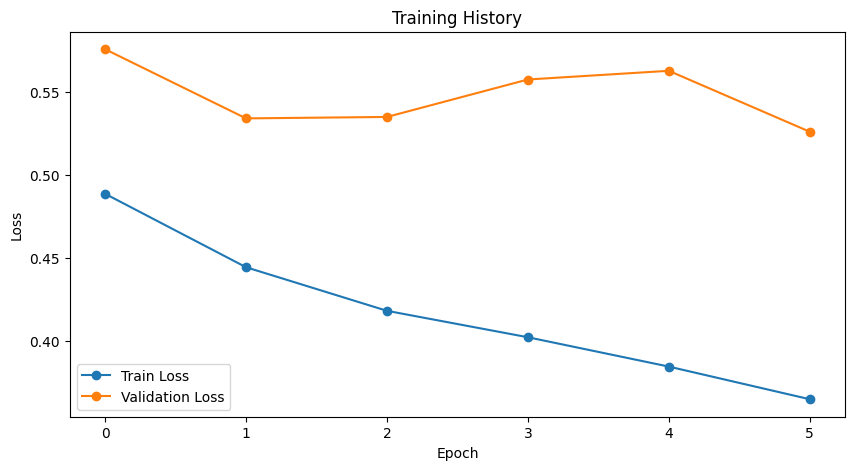

In [46]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history["valid_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training History"
)

plt.legend()

plt.show()

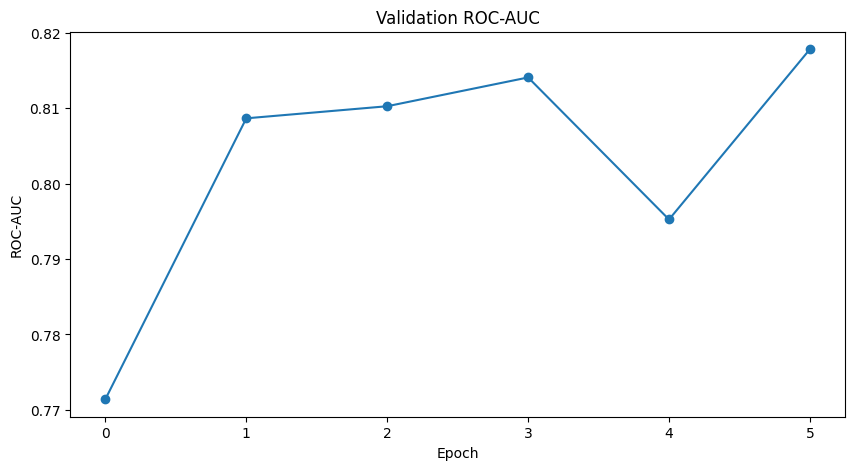

In [47]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history["valid_auc"],
    marker="o"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "ROC-AUC"
)

plt.title(
    "Validation ROC-AUC"
)

plt.show()

### Load best model in eval mode

In [48]:
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_knee_model.pth",
        map_location=DEVICE
    )
)

model.eval()

print(
    "Best model loaded."
)

Best model loaded.


### Define test dataset

In [49]:
test_dataset = HDF5KneeDataset(
    dataframe=test,
    h5_path=TEST_INPUT,
    targets=None,
    transform=valid_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

print("Test studies:", len(test_dataset))

Test studies: 3


### Generate predictions for submission

In [50]:
model.eval()

test_predictions = []

test_ids = []

with torch.no_grad():

    for images, study_ids in tqdm(
        test_loader,
        desc="Predicting"
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        logits = model(
            images
        )

        probabilities = (
            torch.sigmoid(
                logits
            )
        )

        test_predictions.append(
            probabilities
            .cpu()
            .numpy()
        )

        test_ids.extend(
            list(study_ids)
        )

Predicting:   0%|          | 0/1 [00:00<?, ?it/s]

In [51]:
test_predictions = np.concatenate(
    test_predictions,
    axis=0
)

submission = pd.DataFrame(
    test_predictions,
    columns=TARGETS
)

submission.insert(
    0,
    "StudyInstanceUID",
    test_ids
)

display(
    submission.head()
)

,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.196436,0.277716,0.716388,0.274321,0.472944,0.233627,0.509549,0.701230,0.190873,0.691976,0.023305,0.002022
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.136435,0.093634,0.175858,0.152980,0.289029,0.223918,0.332949,0.527996,0.222124,0.172849,0.074981,0.033992
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.091774,0.158742,0.230976,0.302236,0.313405,0.282071,0.661965,0.617915,0.108531,0.338260,0.039134,0.014706


In [52]:
print(
    "Minimum prediction:",
    submission[TARGETS]
    .min()
    .min()
)

print(
    "Maximum prediction:",
    submission[TARGETS]
    .max()
    .max()
)

Minimum prediction: 0.00202248920686543
Maximum prediction: 0.7163878679275513


In [53]:
print(
    "Sample columns:"
)

print(
    sample_submission.columns.tolist()
)

print(
    "\nOur columns:"
)

print(
    submission.columns.tolist()
)

Sample columns:
['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']

Our columns:
['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


In [54]:
submission = submission[
    sample_submission.columns
]

In [55]:
SUBMISSION_PATH = (
    "/kaggle/working/"
    "submission.csv"
)

submission.to_csv(
    SUBMISSION_PATH,
    index=False
)

print(
    "Submission saved:"
)

print(
    SUBMISSION_PATH
)

Submission saved:
/kaggle/working/submission.csv


In [56]:
submission_check = pd.read_csv(
    SUBMISSION_PATH
)

assert list(
    submission_check.columns
) == list(
    sample_submission.columns
)

assert len(
    submission_check
) == len(
    sample_submission
)

assert (
    submission_check[
        TARGETS
    ].isna()
    .sum()
    .sum()
    == 0
)

assert (
    submission_check[
        TARGETS
    ].values >= 0
).all()

assert (
    submission_check[
        TARGETS
    ].values <= 1
).all()

print(
    "================================"
)

print(
    "SUBMISSION VALIDATION PASSED"
)

print(
    "================================"
)

display(
    submission_check.head()
)

SUBMISSION VALIDATION PASSED


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.196436,0.277716,0.716388,0.274321,0.472944,0.233627,0.509549,0.701230,0.190873,0.691976,0.023305,0.002022
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.136435,0.093634,0.175858,0.152980,0.289029,0.223918,0.332949,0.527996,0.222124,0.172849,0.074981,0.033992
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.091774,0.158742,0.230976,0.302236,0.313405,0.282071,0.661965,0.617915,0.108531,0.338260,0.039134,0.014706


In [57]:
# FINAL SUBMISSION

submission = submission[
    sample_submission.columns
].copy()

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("submission.csv created successfully!")
print(submission.shape)
display(submission.head())

submission.csv created successfully!
(3, 13)


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.196436,0.277716,0.716388,0.274321,0.472944,0.233627,0.509549,0.701230,0.190873,0.691976,0.023305,0.002022
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.136435,0.093634,0.175858,0.152980,0.289029,0.223918,0.332949,0.527996,0.222124,0.172849,0.074981,0.033992
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.091774,0.158742,0.230976,0.302236,0.313405,0.282071,0.661965,0.617915,0.108531,0.338260,0.039134,0.014706


In [58]:
import os

path = "/kaggle/working/submission.csv"

print("Exists:", os.path.exists(path))

if os.path.exists(path):
    print("File size:", os.path.getsize(path), "bytes")
    print("Ready for Kaggle submission!")

Exists: True
File size: 719 bytes
Ready for Kaggle submission!
